# Task 2 – Netflix Content Type Prediction Model

**Auspify Technologies | Machine Learning Internship**  
**Objective:** Build a supervised machine-learning model that predicts whether a Netflix catalogue title is a **Movie** or a **TV Show** using available content metadata.

This notebook follows the task workflow: select relevant features, encode categorical/text fields, train classification models, evaluate performance, and compare model accuracy.

> **Important modelling decision:** `duration` is deliberately excluded because values such as `90 min` and `2 Seasons` almost directly disclose the target class. `show_id` and `title` are also excluded because they are identifiers/high-cardinality labels rather than general content attributes.

## 1. Import libraries and project functions

The accompanying `content_type_prediction.py` file contains the reusable preprocessing, training, evaluation, and output-generation functions. Keep it in the same folder as this notebook.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

from content_type_prediction import (
    prepare_dataset,
    run_project,
    FEATURE_COLUMNS,
    RANDOM_STATE,
)

DATASET_PATH = Path("Dataset.csv")
assert DATASET_PATH.exists(), "Dataset.csv must be in the same folder as this notebook."
print("Dataset found:", DATASET_PATH.resolve())
print("Random state:", RANDOM_STATE)

Dataset found: /mnt/data/Task_2_Content_Type_Prediction/Dataset.csv
Random state: 42


## 2. Load and inspect the dataset

The supplied Netflix dataset contains catalogue metadata. We first inspect its dimensions, sample rows, data types, missing values, duplicates, and target distribution.

In [2]:
df = pd.read_csv(DATASET_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())
print("\nLast five records:")
display(df.tail())
print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))
print("\nDuplicate rows:", int(df.duplicated().sum()))
print("\nData types:")
df.dtypes.to_frame("Data type")

Dataset shape: 8,790 rows × 10 columns


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Last five records:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,6/7/2018,2016,TV-Y7,1 Season,Kids' TV



Missing values by column:


,Missing values
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0



Duplicate rows: 0

Data types:


,Data type
show_id,object
type,object
title,object
director,object
country,object
date_added,object
release_year,int64
rating,object
duration,object
listed_in,object


## 3. Explore the target variable

The target column is `type`. The supplied file contains two classes: Movie and TV Show. The class counts are not equal, so the train/test split is stratified to preserve their proportions.

,Number of titles
type,
Movie,6126
TV Show,2664


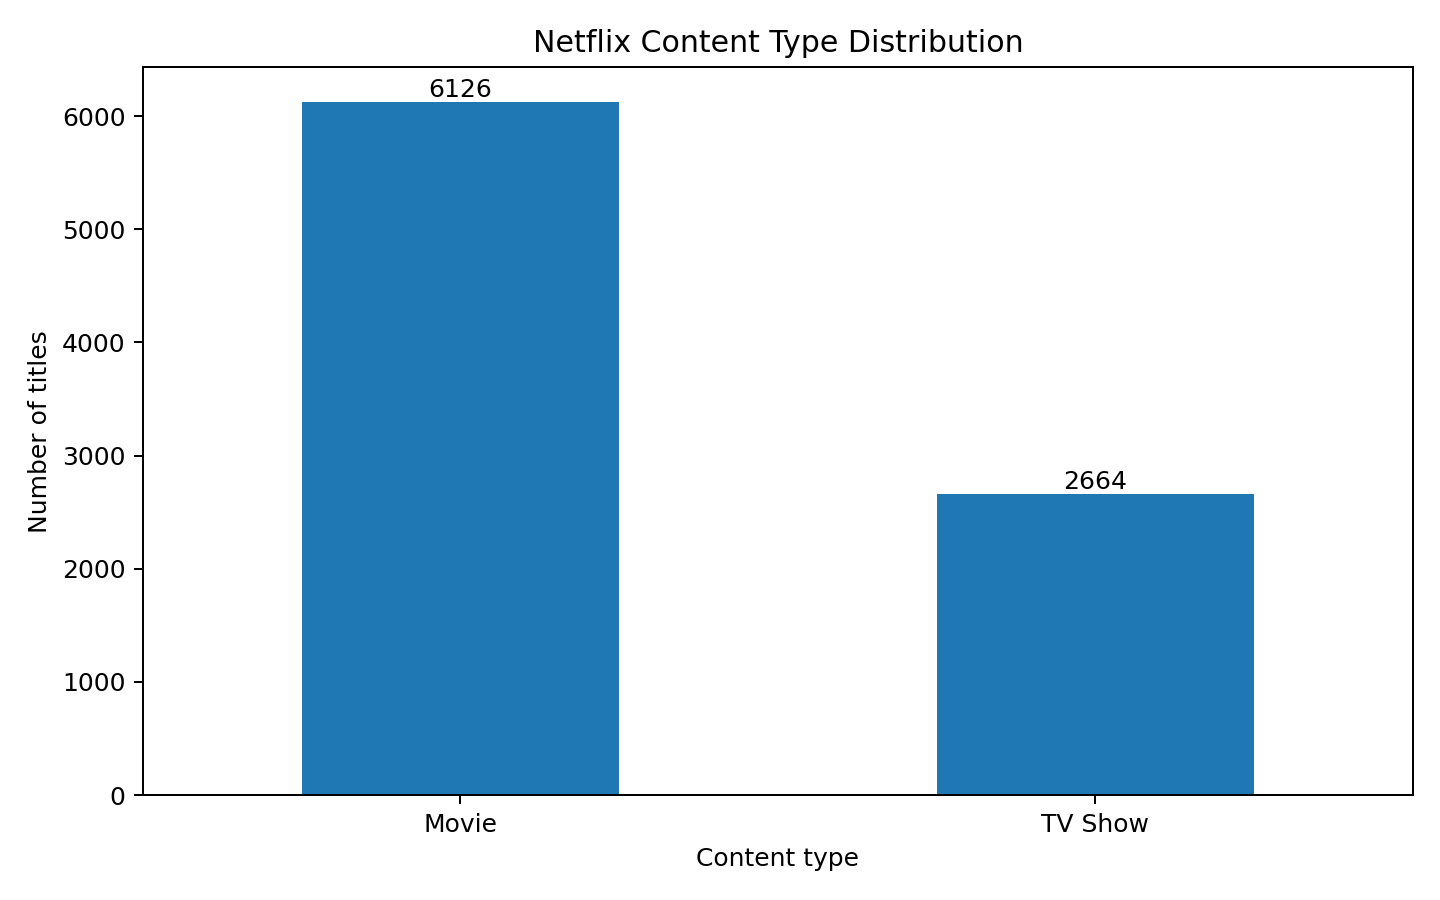

In [3]:
target_counts = df["type"].value_counts().reindex(["Movie", "TV Show"])
display(target_counts.rename("Number of titles").to_frame())
display(Image(filename="screenshots/content_type_distribution.png"))

## 4. Select features and prepare data

The model uses:

- `release_year`, `date_added_year`, `date_added_month` – numerical/date-derived features
- `rating` – one-hot encoded categorical feature
- `director`, `country`, `listed_in` – text/multi-value metadata transformed with TF-IDF

The prediction target is `type`. The dataset identifier (`show_id`), title (`title`), and duration (`duration`) are not used as predictors. `duration` is excluded specifically to avoid a near-direct shortcut to the answer.

In [4]:
X, y, clean_df = prepare_dataset(DATASET_PATH)
print("Prepared feature columns:", FEATURE_COLUMNS)
print("Feature matrix shape before text encoding:", X.shape)
print("Target classes:", sorted(y.unique()))
display(X.head())

Prepared feature columns: ['release_year', 'date_added_year', 'date_added_month', 'rating', 'director', 'country', 'listed_in']
Feature matrix shape before text encoding: (8790, 7)
Target classes: ['Movie', 'TV Show']


,release_year,date_added_year,date_added_month,rating,director,country,listed_in
0,2020,2021,9,PG-13,Kirsten Johnson,United States,Documentaries
1,2021,2021,9,TV-MA,Julien Leclercq,France,"Crime TV Shows, International TV Shows, TV Act..."
2,2021,2021,9,TV-MA,Mike Flanagan,United States,"TV Dramas, TV Horror, TV Mysteries"
3,2021,2021,9,TV-PG,Bruno Garotti,Brazil,"Children & Family Movies, Comedies"
4,1993,2021,9,TV-MA,Haile Gerima,United States,"Dramas, Independent Movies, International Movies"


## 5. Train/test split and model training

We use an 80/20 stratified holdout split with a fixed random seed. Three classifiers are compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest

A majority-class dummy classifier is included as a baseline. Preprocessing is fitted inside each model pipeline using training data, helping prevent preprocessing leakage from the test set.

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
display(y_train.value_counts(normalize=True).rename("Training proportion").to_frame())
display(y_test.value_counts(normalize=True).rename("Testing proportion").to_frame())

Training rows: 7,032
Testing rows:  1,758


,Training proportion
type,
Movie,0.696957
TV Show,0.303043


,Testing proportion
type,
Movie,0.696815
TV Show,0.303185


In [6]:
# Train all models, compare held-out performance, and save charts/results.
project = run_project(DATASET_PATH, ".")
results = project["results"]
best_model_name = project["best_name"]
best_model = project["best_pipeline"]
y_test_actual = project["y_test"]
y_test_predicted = project["best_predictions"]

display(results.style.format({
    "Accuracy": "{:.4%}",
    "Precision (macro)": "{:.4%}",
    "Recall (macro)": "{:.4%}",
    "F1 (macro)": "{:.4%}",
}))
print("Best model selected by macro F1:", best_model_name)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,99.9431%,99.9592%,99.9062%,99.9327%
1,Decision Tree,99.4881%,99.4201%,99.3677%,99.3939%
2,Random Forest,98.5210%,97.8806%,98.6738%,98.2644%
3,Majority-class baseline,69.6815%,34.8407%,50.0000%,41.0660%


Best model selected by macro F1: Logistic Regression


## 6. Compare model accuracy

The accuracy chart compares each classifier with the majority-class baseline on the same held-out test set.

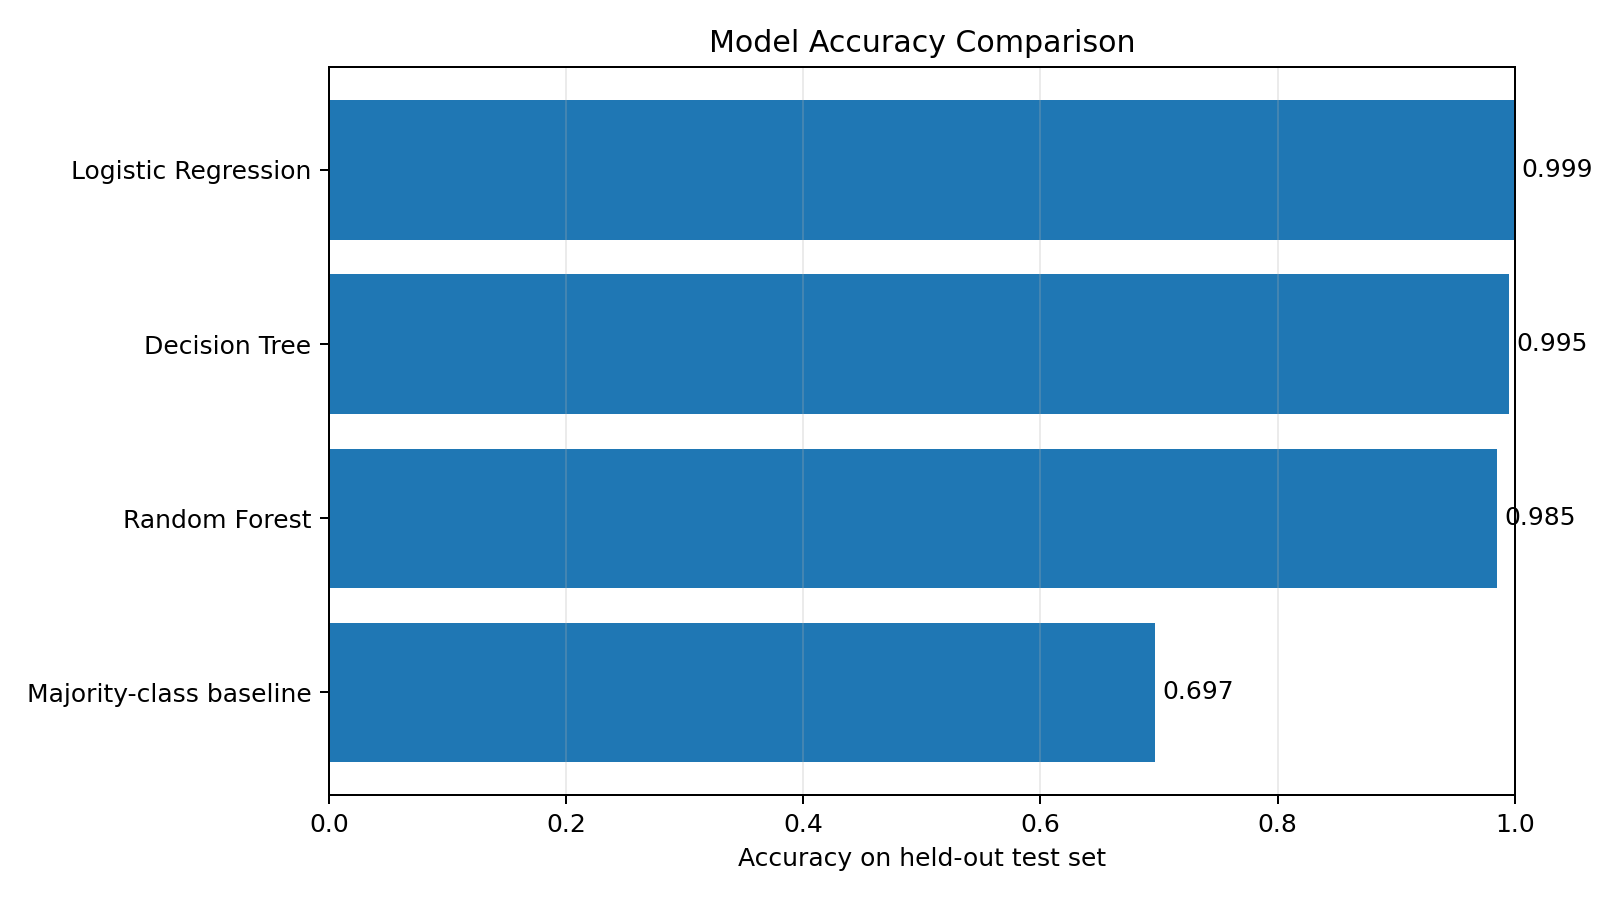

In [7]:
display(Image(filename="screenshots/model_accuracy_comparison.png"))

## 7. Evaluate the selected model

The best model is selected using macro F1, which gives equal importance to both classes. We review accuracy, precision, recall, F1-score, and the confusion matrix rather than relying on accuracy alone.

Classification report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758

Confusion matrix (rows = actual, columns = predicted):
[[1225    0]
 [   1  532]]


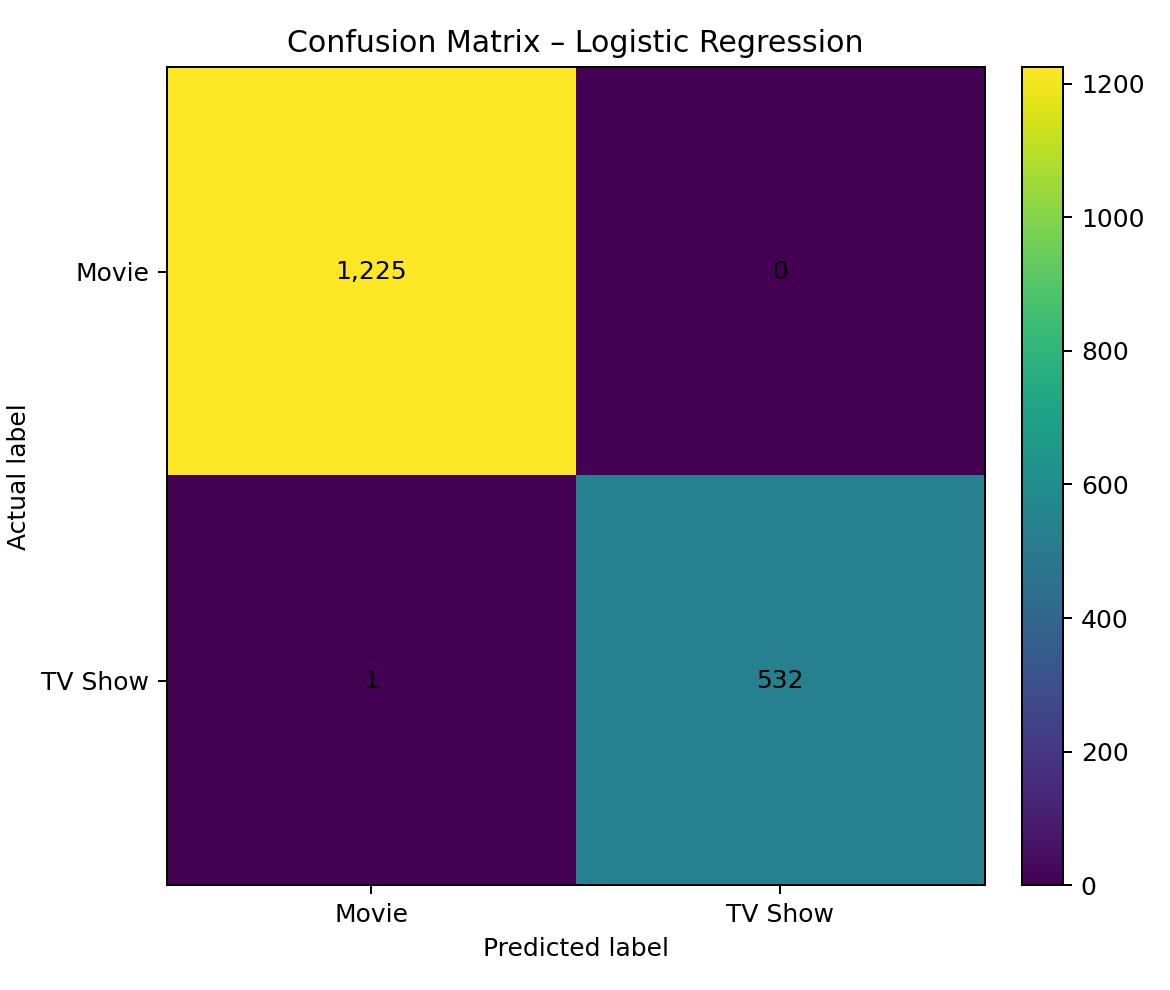

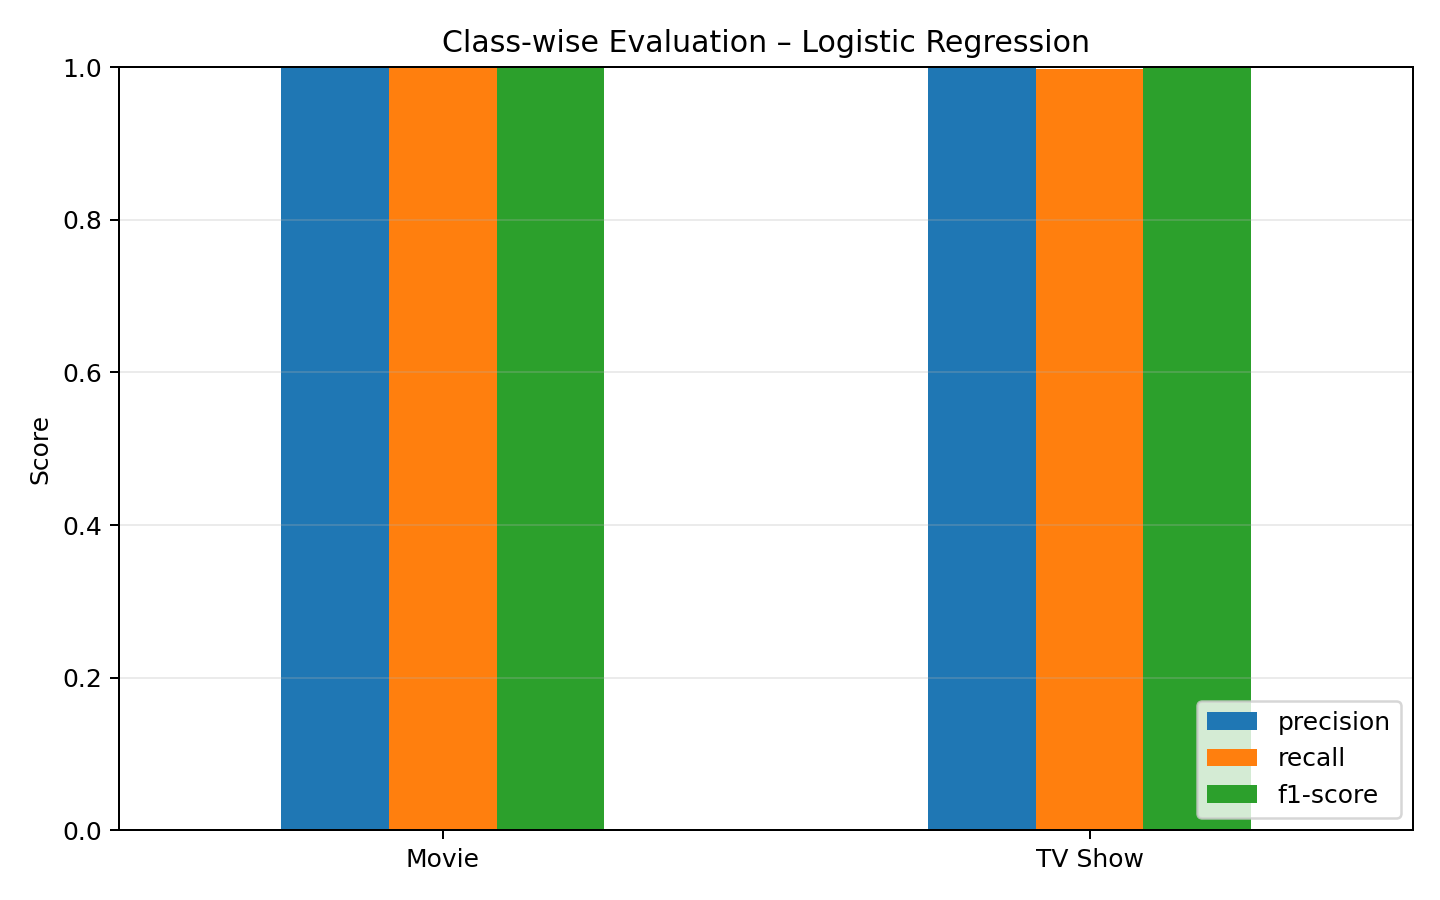

In [8]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification report:")
print(classification_report(y_test_actual, y_test_predicted, zero_division=0))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_actual, y_test_predicted, labels=["Movie", "TV Show"]))
display(Image(filename="screenshots/best_model_confusion_matrix.png"))
display(Image(filename="screenshots/classwise_metrics.png"))

## 8. Inspect sample predictions

The following table shows a sample of test records with their actual and predicted content types. The output CSV in `outputs/` contains up to 500 test predictions.

In [9]:
sample_predictions = pd.read_csv("outputs/sample_test_predictions.csv")
display(sample_predictions[[
    "release_year", "date_added_year", "date_added_month", "rating",
    "director", "country", "listed_in", "actual_type", "predicted_type", "correct"
]].head(12))

,release_year,date_added_year,date_added_month,rating,director,country,listed_in,actual_type,predicted_type,correct
0,2017,2018,5,TV-PG,"Fluvio Iannuci, Roly Santos",Italy,"Documentaries, International Movies",Movie,Movie,True
1,1991,2018,4,G,"Phil Nibbelink, Simon Wells",United States,Children & Family Movies,Movie,Movie,True
2,2019,2019,5,TV-MA,Sudabeh Mortezai,Austria,"Dramas, Independent Movies, International Movies",Movie,Movie,True
3,2015,2015,12,TV-MA,Alik Sakharov,United States,Movies,Movie,Movie,True
4,2015,2016,7,TV-MA,Not Given,United States,"TV Comedies, TV Dramas",TV Show,TV Show,True
5,2020,2020,8,TV-14,Shamzu Zayba,India,"Comedies, International Movies, Romantic Movies",Movie,Movie,True
6,2018,2019,3,TV-MA,Not Given,United States,TV Action & Adventure,TV Show,TV Show,True
7,2016,2018,4,TV-14,Padmakumar Narasimhamurthy,India,"Dramas, Independent Movies, International Movies",Movie,Movie,True
8,2017,2018,7,TV-PG,Gafoor Y. Elliyaas,India,"Dramas, Independent Movies, International Movies",Movie,Movie,True
9,2016,2017,12,R,Lydia Tenaglia,Mexico,Documentaries,Movie,Movie,True


## 9. Robustness check: effect of genre metadata

The `listed_in` field contains genre labels and some labels explicitly include the TV category (for example, TV-specific genres). To make this influence transparent, the script repeats Logistic Regression on the same train/test rows with `listed_in` removed. This is a feature-ablation check, not a separate task.

,Feature set,Accuracy,Macro F1
0,All selected metadata,99.9431%,99.9327%
1,Without listed_in genres,94.8237%,93.8317%


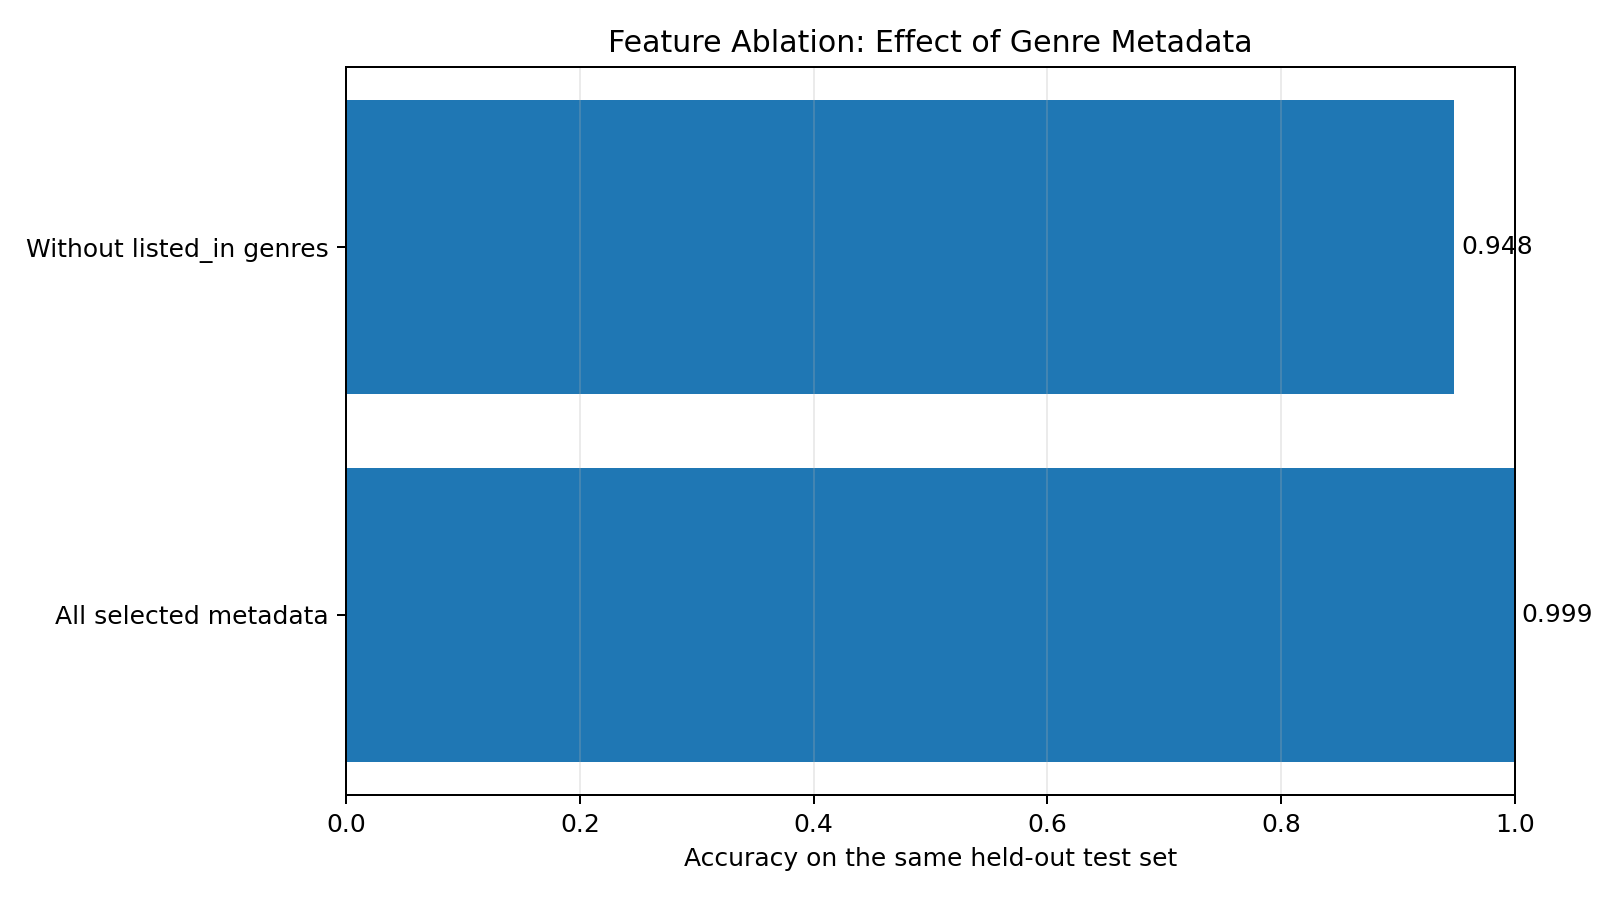

In [10]:
ablation = project["ablation_results"]
display(ablation.style.format({"Accuracy": "{:.4%}", "Macro F1": "{:.4%}"}))
display(Image(filename="screenshots/genre_feature_ablation.png"))

## 10. Project conclusion and limitations

The model successfully classifies Netflix titles into Movie and TV Show categories using catalogue metadata. Logistic Regression performed best among the tested models on the stratified holdout set.

**Interpretation:** The full-feature result is very high partly because genre metadata contains TV-specific labels. When `listed_in` is removed, performance decreases; this demonstrates that genre information is highly predictive in this dataset. The result should therefore be interpreted as performance on this Netflix catalogue, not as a guarantee on new platforms or future unseen catalogues.

**Limitations:**
- This is a single random train/test split from one Netflix catalogue dataset.
- Some metadata fields, especially genre labels, are strongly associated with the target class.
- The dataset does not represent all streaming platforms or future content.
- The project predicts catalogue type; it does not predict popularity, viewer numbers, or commercial success.

**Conclusion:** The task demonstrates feature selection, text/categorical encoding, supervised classification, model comparison, and evaluation using a reproducible machine-learning pipeline.

In [11]:
print("Final result summary:")
print("Rows used:", project["summary"]["rows_used"])
print("Training rows:", project["summary"]["train_rows"])
print("Testing rows:", project["summary"]["test_rows"])
print("Best model:", project["summary"]["best_model"])
print("Accuracy:", f"{project['summary']['metrics']['Accuracy']:.4%}")
print("Macro F1:", f"{project['summary']['metrics']['F1 (macro)']:.4%}")
print("Accuracy without listed_in:", f"{project['summary']['accuracy_without_listed_in_genres']:.4%}")
print("\nGenerated files are saved in screenshots/, charts/, and outputs/.")

Final result summary:
Rows used: 8790
Training rows: 7032
Testing rows: 1758
Best model: Logistic Regression
Accuracy: 99.9431%
Macro F1: 99.9327%
Accuracy without listed_in: 94.8237%

Generated files are saved in screenshots/, charts/, and outputs/.
